로그 찾기:
  exp_llm_adamw: /kaggle/input/notebooks/shindoooonggy/babylm-python-adamw/exp_llm_adamw/pretrain_log.json
  exp_l5_pretrain: /kaggle/input/notebooks/shindoooonggy/l5a-muon005-pretrain-euc-spec-full/exp_l5_pretrain/pretrain_log.json
  exp_l6_pretrain: /kaggle/input/notebooks/shindoooonggy/l6a-muon005-pretrain-window-rho/exp_l6_pretrain/pretrain_log.json
  exp_l7: /kaggle/input/notebooks/shindoooonggy/l7-muon005-fullspec005-decay01/exp_l7/pretrain_log.json

===== 목표 loss 도달 시간 =====


,방법,전체_분,최종_loss,평균_초_per_step,AdamW off 최종(3.2881) 도달_분,Muon off 최종(3.3800) 도달_분,AdamW 종료 시각(65분)의 loss
0,AdamW off,65.0,3.2881,0.204,65.0,56.1,3.2881
1,AdamW decay-euc ρ0.05,77.3,3.2807,0.242,76.2,59.4,3.3317
2,Muon off,96.9,3.3800,0.304,NaN,85.5,3.4112
3,Muon decay-spec ρ0.02,121.7,3.2299,0.381,96.1,80.1,3.4112
4,Muon decay-spec ρ0.05,121.7,3.2429,0.382,103.6,82.2,3.4112
5,Muon full-spec ρ0.05,219.8,3.2725,0.689,206.4,140.5,3.5369
6,Muon full-spec ρ0.008,240.5,3.2648,0.754,213.3,86.8,3.4179



※ 참고: L1(10/1)은 torch 2.10, L5A 이후는 torch 2.11 환경. 같은 Muon 코드가 0.295 → 0.33초/step으로 약 10% 느려진 기록이 있음
   → AdamW vs Muon 시간 비교는 이 정도 환경 차이를 감안해서 해석. Muon끼리 비교(off / decay / full)는 같은 환경
※ WSD 스케줄이라 loss가 마지막 20% 감쇠 구간에서 크게 떨어짐 → 도달 시점이 대부분 감쇠 구간 안에 있을 것


/tmp/ipykernel_16/2946413276.py:72: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(c['min'], c.loss, '-o', ms=2.5, lw=1.4, label=name, ls='--' if 'AdamW' in name else '-')
/tmp/ipykernel_16/2946413276.py:77: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig('/kaggle/working/time_to_target.png', dpi=150); plt.show()
/tmp/ipykernel_16/2946413276.py:77: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig('/kaggle/working/time_to_target.png', dpi=150); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:1

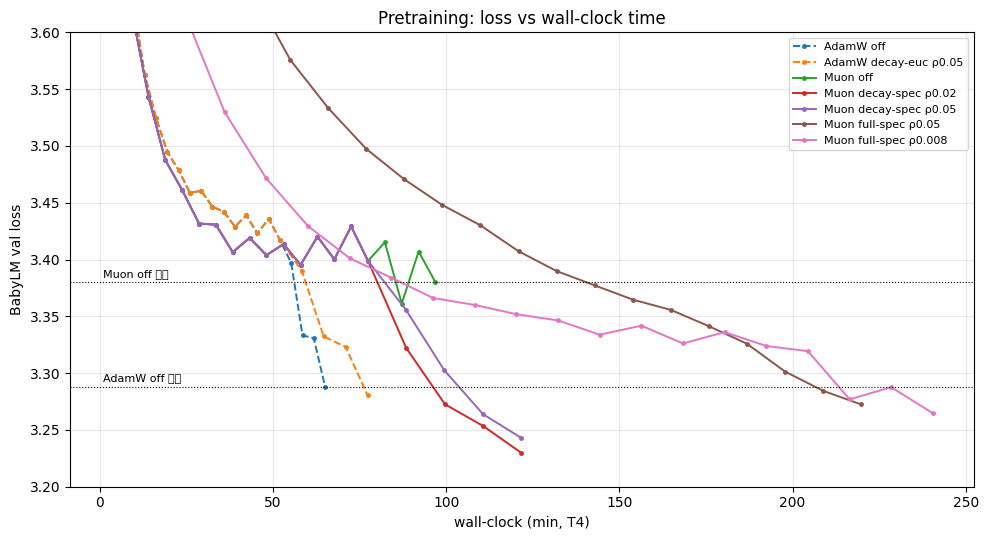

In [1]:
# ============ T1: 목표 loss 도달 시간 (기존 사전학습 로그로 계산, GPU 불필요) ============
import glob, json, numpy as np, pandas as pd, matplotlib.pyplot as plt

def load_log(folder):
    h = glob.glob(f'/kaggle/input/**/{folder}/pretrain_log.json', recursive=True)
    if not h: print(f'※ {folder} 로그 없음 — Add Input 확인 (건너뜀)'); return None
    print(f'  {folder}: {h[0]}')
    return json.load(open(h[0]))

def build(log, branch, prefix='shared', prefix_log=None):
    """공통 구간 + 갈래를 이어 붙인 (누적 분, step, 검증 loss) 곡선"""
    pts, t = [(0.0, 0, np.nan)], 0.0
    entries = ((prefix_log or log).get(prefix, []) if prefix else []) + log[branch]
    for e in entries:
        t += e['sec'] / 60; pts.append((t, e['step'], e['val_loss']))
    return pd.DataFrame(pts, columns=['min', 'step', 'loss'])

def time_to(c, target):
    c = c.dropna(); prev = None
    for r in c.itertuples():
        if r.loss <= target:
            if prev is None: return r.min
            f = (prev.loss - target) / (prev.loss - r.loss)          # 선형 보간
            return prev.min + f * (r.min - prev.min)
        prev = r
    return np.nan

def loss_at(c, minutes):
    c = c.dropna()
    return float(np.interp(minutes, c['min'], c['loss'])) if minutes <= c['min'].max() else np.nan

print('로그 찾기:')
L1, L5A, L6A, L7 = load_log('exp_llm_adamw'), load_log('exp_l5_pretrain'), load_log('exp_l6_pretrain'), load_log('exp_l7')

C = {}
if L1:
    C['AdamW off'] = build(L1, 'pre_off')
    C['AdamW decay-euc ρ0.05'] = build(L1, 'pre_sam')
if L6A:
    C['Muon off'] = build(L6A, 'pre_off_repro')
    C['Muon decay-spec ρ0.02'] = build(L6A, 'pre_decay_spec_0.02')
    C['Muon decay-spec ρ0.05'] = build(L6A, 'pre_decay_spec_0.05')
if L7:
    C['Muon full-spec ρ0.05'] = build(L7, 'pre_full_spec_0.05', prefix=None)
if L5A:
    C['Muon full-spec ρ0.008'] = build(L5A, 'pre_full_spec', prefix=None)

TARGETS = {}
if 'AdamW off' in C: TARGETS['AdamW off 최종'] = C['AdamW off'].loss.iloc[-1]
if 'Muon off' in C:  TARGETS['Muon off 최종'] = C['Muon off'].loss.iloc[-1]
ADAM_T = C['AdamW off']['min'].iloc[-1] if 'AdamW off' in C else None

rows = []
for name, c in C.items():
    r = dict(방법=name, 전체_분=round(c['min'].iloc[-1], 1), 최종_loss=round(c.loss.iloc[-1], 4),
             평균_초_per_step=round(c['min'].iloc[-1] * 60 / c['step'].iloc[-1], 3))
    for tn, tv in TARGETS.items():
        r[f'{tn}({tv:.4f}) 도달_분'] = round(time_to(c, tv), 1)
    if ADAM_T: r[f'AdamW 종료 시각({ADAM_T:.0f}분)의 loss'] = round(loss_at(c, ADAM_T), 4)
    rows.append(r)
df = pd.DataFrame(rows)
print('\n===== 목표 loss 도달 시간 =====')
display(df)
df.to_csv('/kaggle/working/time_to_target.csv', index=False)

print('\n※ 참고: L1(10/1)은 torch 2.10, L5A 이후는 torch 2.11 환경. 같은 Muon 코드가 0.295 → 0.33초/step으로 약 10% 느려진 기록이 있음')
print('   → AdamW vs Muon 시간 비교는 이 정도 환경 차이를 감안해서 해석. Muon끼리 비교(off / decay / full)는 같은 환경')
print('※ WSD 스케줄이라 loss가 마지막 20% 감쇠 구간에서 크게 떨어짐 → 도달 시점이 대부분 감쇠 구간 안에 있을 것')

fig, ax = plt.subplots(figsize=(10, 5.5))
for name, c in C.items():
    ax.plot(c['min'], c.loss, '-o', ms=2.5, lw=1.4, label=name, ls='--' if 'AdamW' in name else '-')
for tn, tv in TARGETS.items():
    ax.axhline(tv, color='k', ls=':', lw=0.8); ax.text(1, tv + 0.005, tn, fontsize=8)
ax.set_ylim(3.2, 3.6); ax.set_xlabel('wall-clock (min, T4)'); ax.set_ylabel('BabyLM val loss')
ax.set_title('Pretraining: loss vs wall-clock time'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('/kaggle/working/time_to_target.png', dpi=150); plt.show()